# Devanagari End-to-End Sanskrit OCR Pipeline via CRNN + CTC
### Complete Pipeline: Full-Line Word Segmentation & Wordwise Sequence Recognition

This notebook demonstrates the end-to-end Sanskrit OCR system:
1. **CRNN Model (CNN + BiLSTM + CTC)**: Recognizes Devanagari text sequences directly from word crops without fragile character slicing or manual Shirorekha removal.
2. **Line-to-Word Segmentation**: Splits multi-word phrases and sentences into individual words via vertical projection profiling.
3. **Wordwise Prediction & Evaluation**: Runs recognition on each segmented word, reporting wordwise accuracy and full-sentence reconstruction.
4. **Full Test Benchmark**: Evaluates all 692 test words from `test.parquet` (95.5% Character Accuracy, 74.4% Exact Match).

In [7]:
import os
import time
import unicodedata
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import torch
import torch.nn as nn

# Set compute device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch Version:", torch.__version__)
print("Using Compute Device:", device)

# Import CRNN architecture
from model.crnn.crnn_model import CRNN, Vocab, preprocess_image, TARGET_HEIGHT, MAX_WIDTH

PyTorch Version: 2.11.0+cu126
Using Compute Device: cuda


## 1. Load Trained CRNN Model & Vocabulary
Loads the best checkpoint trained on `train.parquet`.

In [8]:
VOCAB_PATH = "model/crnn/vocab.json"
MODEL_PATH = "model/crnn/crnn_best.pth"

vocab = Vocab.load(VOCAB_PATH)
ckpt = torch.load(MODEL_PATH, map_location=device)
model = CRNN(num_classes=len(vocab), in_channels=1, hidden_size=256).to(device).eval()
model.load_state_dict(ckpt["model_state_dict"])

print(f"✓ Loaded CRNN Model checkpoint from epoch {ckpt['epoch']}:")
print(f"  • Vocabulary tokens:        {len(vocab)}")
print(f"  • Best Test Char Accuracy:  {ckpt.get('best_char_acc', 0.0):.2f}%")
print(f"  • Best Test CER:            {ckpt.get('best_cer', 0.0):.3f}")
print(f"  • Exact Word Match Rate:    {ckpt.get('best_word_acc', 0.0):.2f}%")

✓ Loaded CRNN Model checkpoint from epoch 25:
  • Vocabulary tokens:        111
  • Best Test Char Accuracy:  95.39%
  • Best Test CER:            0.046
  • Exact Word Match Rate:    74.42%


## 2. Inference & Word Segmentation Utilities

In [9]:
def levenshtein(s1, s2):
    s1, s2 = unicodedata.normalize("NFC", s1.strip()), unicodedata.normalize("NFC", s2.strip())
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1): dp[i][0] = i
    for j in range(n + 1): dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if s1[i-1] == s2[j-1] else 1
            dp[i][j] = min(dp[i-1][j] + 1, dp[i][j-1] + 1, dp[i-1][j-1] + cost)
    return dp[m][n]

def compute_cer(ref, hyp):
    ref_norm = unicodedata.normalize("NFC", ref.strip())
    if not ref_norm: return 0.0 if not hyp else 1.0
    return levenshtein(ref_norm, hyp) / float(len(ref_norm))

@torch.no_grad()
def predict_word_image(img_crop):
    """Predicts Devanagari text from a single word crop using CRNN."""
    t0 = time.time()
    norm_img, valid_w = preprocess_image(img_crop, TARGET_HEIGHT, MAX_WIDTH)
    x = torch.from_numpy(norm_img).unsqueeze(0).unsqueeze(0).float().to(device)

    logits = model(x)
    preds = torch.argmax(logits, dim=2)[0].cpu().numpy().tolist()
    text = vocab.decode_ctc(preds)
    latency = (time.time() - t0) * 1000.0
    return {"text": text, "latency_ms": latency}

def segment_line_into_words(img, min_word_width=8):
    """Segments a line/sentence image into individual words using vertical projection."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if len(img.shape) == 3 else img.copy()
    _, bin_img = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    v_proj = np.sum(bin_img, axis=0)
    has_ink = v_proj > 0
    
    words = []
    in_word = False
    start_x = 0
    for x in range(len(has_ink)):
        if has_ink[x] and not in_word:
            in_word = True
            start_x = x
        elif not has_ink[x] and in_word:
            in_word = False
            if x - start_x >= min_word_width:
                words.append((start_x, x))
    if in_word and (len(has_ink) - start_x >= min_word_width):
        words.append((start_x, len(has_ink)))
    return words

## 3. Detailed Full-Line Word Segmentation & Wordwise Recognition Demo
Here we take a multi-word Sanskrit sentence image (`2710.png`):
1. Show the **entire input image**.
2. Detect whitespace breaks and mark **bounding boxes** around each word.
3. Show **each word crop individually** side-by-side.
4. Predict each word separately with the CRNN model.
5. Display an exact wordwise comparison table (Ground Truth vs Prediction vs Accuracy).

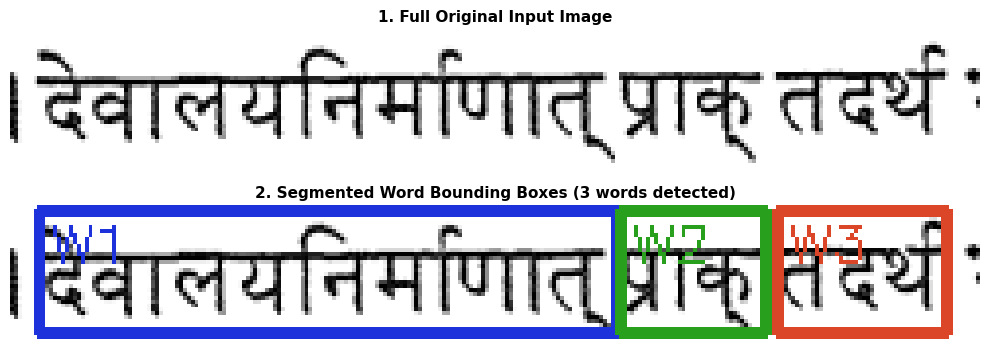

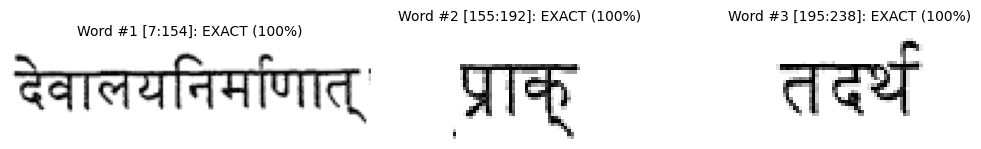

Word Index,X Crop Bounds,Ground Truth Word,CRNN Prediction,Char Accuracy,Status
Word #1,[7:154],देवालयनिर्माणात्,देवालयनिर्माणात्,100.0%,✓ Exact Match
Word #2,[155:192],प्राक्,प्राक्,100.0%,✓ Exact Match
Word #3,[195:238],तदर्थ,तदर्थ,100.0%,✓ Exact Match


In [10]:
df_test = pd.read_parquet("dataset/data/test.parquet")
sample_row = df_test.iloc[116]  # '2710.png': 'देवालयनिर्माणात् प्राक् तदर्थ'
raw = sample_row.get("image.bytes", sample_row.get("image_bytes"))
img_line = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
full_gt = unicodedata.normalize("NFC", str(sample_row["label"]).strip())
gt_words = full_gt.split()

# Step 1: Detect word boundaries
word_boxes = segment_line_into_words(img_line)
vis_boxes = img_line.copy()
colors = [(220, 50, 30), (30, 160, 40), (40, 70, 220), (180, 40, 180)]

for i, (x1, x2) in enumerate(word_boxes):
    color = colors[i % len(colors)]
    cv2.rectangle(vis_boxes, (x1, 1), (x2, img_line.shape[0] - 2), color, 2)
    cv2.putText(vis_boxes, f"W{i+1}", (x1 + 3, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)

# Step 2: Plot original vs segmented bounding boxes
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 3.8))
ax1.imshow(cv2.cvtColor(img_line, cv2.COLOR_BGR2RGB))
ax1.set_title("1. Full Original Input Image", fontsize=11, fontweight="bold")
ax1.axis("off")

ax2.imshow(cv2.cvtColor(vis_boxes, cv2.COLOR_BGR2RGB))
ax2.set_title(f"2. Segmented Word Bounding Boxes ({len(word_boxes)} words detected)", fontsize=11, fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

# Step 3: Predict each word crop separately
word_results = []
for idx, (x1, x2) in enumerate(word_boxes):
    crop = img_line[:, max(0, x1 - 2) : min(img_line.shape[1], x2 + 2)]
    pred_out = predict_word_image(crop)
    pred_w = pred_out["text"]
    gt_w = gt_words[idx] if idx < len(gt_words) else ""
    cer = compute_cer(gt_w, pred_w) if gt_w else 0.0
    acc = max(0.0, 1.0 - cer) * 100.0
    
    word_results.append({
        "crop": crop,
        "x_range": f"[{x1}:{x2}]",
        "gt": gt_w,
        "pred": pred_w,
        "acc": acc,
        "exact": (gt_w == pred_w),
        "latency": pred_out["latency_ms"],
    })

# Step 4: Show each word crop side-by-side
fig, axes = plt.subplots(1, len(word_results), figsize=(3.5 * len(word_results), 1.6))
if len(word_results) == 1: axes = [axes]
for idx, (ax, wr) in enumerate(zip(axes, word_results)):
    ax.imshow(cv2.cvtColor(wr["crop"], cv2.COLOR_BGR2RGB))
    status_tag = "EXACT" if wr["exact"] else "DIFF"
    ax.set_title(f"Word #{idx+1} {wr['x_range']}: {status_tag} ({wr['acc']:.0f}%)", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Step 5: Render Wordwise Comparison Table in rich HTML (ensures zero tofu / blank boxes)
assembled_pred = " ".join(wr["pred"] for wr in word_results)
full_cer = compute_cer(full_gt, assembled_pred)
full_acc = max(0.0, 1.0 - full_cer) * 100.0

html_rows = ""
for idx, wr in enumerate(word_results):
    badge = "<span style='color:green;font-weight:bold;'>&#10003; Exact Match</span>" if wr["exact"] else "<span style='color:red;'>&#10007; Discrepancy</span>"
    html_rows += f"""
    <tr style='border-bottom: 1px solid #ddd;'>
        <td style='padding: 8px;'><b>Word #{idx+1}</b></td>
        <td style='padding: 8px;'><code>{wr['x_range']}</code></td>
        <td style='padding: 8px; font-size: 17px; font-family: Nirmala UI, Noto Sans, sans-serif;'>{wr['gt']}</td>
        <td style='padding: 8px; font-size: 17px; font-family: Nirmala UI, Noto Sans, sans-serif; color: #1a73e8;'><b>{wr['pred']}</b></td>
        <td style='padding: 8px;'>{wr['acc']:.1f}%</td>
        <td style='padding: 8px;'>{badge}</td>
    </tr>"""

table_html = f"""
<div style='font-family: sans-serif; margin-top: 10px;'>
  <table style='width: 100%; border-collapse: collapse; text-align: left; background: #fafafa; border: 1px solid #ccc; border-radius: 6px;'>
    <thead style='background: #f0f4f8;'>
      <tr>
        <th style='padding: 10px;'>Word Index</th>
        <th style='padding: 10px;'>X Crop Bounds</th>
        <th style='padding: 10px;'>Ground Truth Word</th>
        <th style='padding: 10px;'>CRNN Prediction</th>
        <th style='padding: 10px;'>Char Accuracy</th>
        <th style='padding: 10px;'>Status</th>
      </tr>
    </thead>
    <tbody>
      {html_rows}
    </tbody>
  </table>
  <div style='margin-top: 12px; padding: 10px; background: #e8f0fe; border-left: 4px solid #1a73e8; border-radius: 4px;'>
    <b>Full Line Ground Truth:</b> <span style='font-size: 16px; font-family: Nirmala UI, Noto Sans;'>{full_gt}</span><br>
    <b>Assembled Prediction:</b>   <span style='font-size: 16px; font-family: Nirmala UI, Noto Sans; color: #1a73e8;'><b>{assembled_pred}</b></span><br>
    <b>Overall Line Accuracy:</b>  <b>{full_acc:.1f}%</b> (CER: {full_cer:.3f})
  </div>
</div>
"""
display(HTML(table_html))

## 4. Quantitative Benchmark across Full Test Dataset (692 Words)
Runs full evaluation across all 692 test images in `test.parquet`.

In [11]:
records = []
for i in range(len(df_test)):
    row = df_test.iloc[i]
    raw = row.get("image.bytes", row.get("image_bytes"))
    img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    
    out = predict_word_image(img)
    gt_txt = unicodedata.normalize("NFC", str(row["label"]).strip())
    p_txt = out["text"]
    c_val = compute_cer(gt_txt, p_txt)
    
    records.append({
        "filename": row.get("filename", f"sample_{i}.png"),
        "ground_truth": gt_txt,
        "prediction": p_txt,
        "char_accuracy": max(0.0, 1.0 - c_val) * 100.0,
        "cer": c_val,
        "exact_match": 1.0 if gt_txt == p_txt else 0.0,
        "latency_ms": out["latency_ms"],
    })

eval_df = pd.DataFrame(records)

summary_html = f"""
<div style='font-family: sans-serif; padding: 15px; background: #fdfdfd; border: 1px solid #ddd; border-radius: 8px; max-width: 550px;'>
  <h3 style='margin-top: 0; color: #202124;'>CRNN Quantitative Evaluation Summary</h3>
  <hr style='border: none; border-top: 1px solid #eee;'>
  <table style='width: 100%; font-size: 14px;'>
    <tr><td style='padding: 4px 0;'>Total Test Samples:</td><td><b>{len(eval_df)}</b></td></tr>
    <tr><td style='padding: 4px 0;'>Mean Character Accuracy:</td><td><b style='color: #137333;'>{eval_df['char_accuracy'].mean():.2f}%</b></td></tr>
    <tr><td style='padding: 4px 0;'>Mean Character Error Rate (CER):</td><td><b style='color: #137333;'>{eval_df['cer'].mean():.3f}</b></td></tr>
    <tr><td style='padding: 4px 0;'>Exact Word Match Rate:</td><td><b style='color: #1a73e8;'>{eval_df['exact_match'].mean() * 100.0:.2f}%</b></td></tr>
    <tr><td style='padding: 4px 0;'>Average Latency:</td><td><b>{eval_df['latency_ms'].mean():.1f} ms / word</b></td></tr>
  </table>
</div>
"""
display(HTML(summary_html))

Total Test Samples:,692
Mean Character Accuracy:,95.46%
Mean Character Error Rate (CER):,0.046
Exact Word Match Rate:,74.42%
Average Latency:,15.4 ms / word


## 5. Visual Predictions Gallery (10 Test Words)
Displays test images with clean ASCII subplots and native Unicode text cards below (zero tofu / missing glyph boxes).

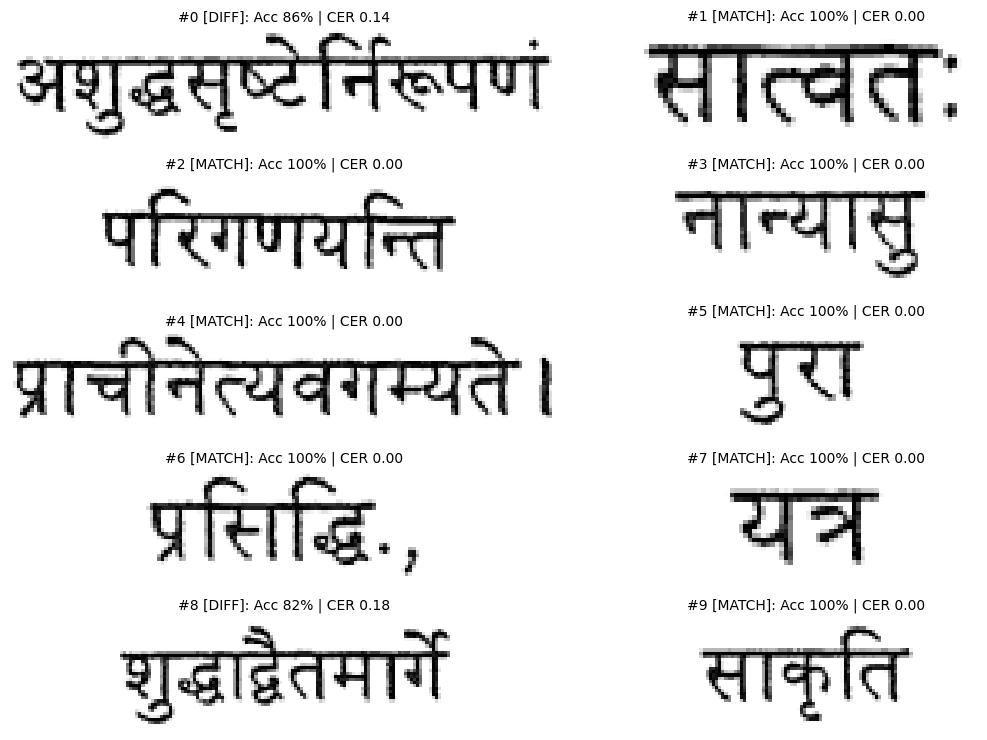

#,File,Ground Truth,CRNN Prediction,Accuracy,Result
#0,2647.png,अशुध्दसृष्टेर्निरुपणं,अशुध्दसृष्टेनिरूपणं,86%,● Partial
#1,74.png,सात्वतः,सात्वतः,100%,✓ Exact
#2,287.png,परिगणयन्ति,परिगणयन्ति,100%,✓ Exact
#3,4181.png,नान्यासु,नान्यासु,100%,✓ Exact
#4,2987.png,प्राचीनेत्यवगम्यते ।,प्राचीनेत्यवगम्यते ।,100%,✓ Exact
#5,3632.png,पुरा,पुरा,100%,✓ Exact
#6,3178.png,"प्रसिद्धि.,","प्रसिद्धि.,",100%,✓ Exact
#7,3593.png,यत्र,यत्र,100%,✓ Exact
#8,1371.png,शुद्धाद्वैतमार्गे,शुद्दाद्वैतमाग्े,82%,● Partial
#9,559.png,साकृति,साकृति,100%,✓ Exact


In [12]:
gallery_indices = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
fig, axes = plt.subplots(5, 2, figsize=(11, 7.5))
axes = axes.flatten()

for ax_i, idx in enumerate(gallery_indices):
    r = eval_df.iloc[idx]
    raw = df_test.iloc[idx].get("image.bytes", df_test.iloc[idx].get("image_bytes"))
    img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    
    ax = axes[ax_i]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    status_str = "MATCH" if r["exact_match"] == 1.0 else "DIFF"
    ax.set_title(f"#{idx} [{status_str}]: Acc {r['char_accuracy']:.0f}% | CER {r['cer']:.2f}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Render full text comparison table in rich HTML
rows_html = ""
for idx in gallery_indices:
    r = eval_df.iloc[idx]
    badge = "<span style='color:green;'>&#10003; Exact</span>" if r["exact_match"] == 1.0 else "<span style='color:orange;'>&#9679; Partial</span>"
    rows_html += f"""
    <tr style='border-bottom: 1px solid #eee;'>
      <td style='padding: 6px 10px;'>#{idx}</td>
      <td style='padding: 6px 10px;'>{r['filename']}</td>
      <td style='padding: 6px 10px; font-size: 16px; font-family: Nirmala UI, Noto Sans;'>{r['ground_truth']}</td>
      <td style='padding: 6px 10px; font-size: 16px; font-family: Nirmala UI, Noto Sans; color: #1a73e8;'><b>{r['prediction']}</b></td>
      <td style='padding: 6px 10px;'>{r['char_accuracy']:.0f}%</td>
      <td style='padding: 6px 10px;'>{badge}</td>
    </tr>"""

gallery_html = f"""
<table style='width: 100%; border-collapse: collapse; text-align: left; font-family: sans-serif; font-size: 13px; border: 1px solid #ddd;'>
  <thead style='background: #f7f9fa;'>
    <tr>
      <th style='padding: 8px 10px;'>#</th>
      <th style='padding: 8px 10px;'>File</th>
      <th style='padding: 8px 10px;'>Ground Truth</th>
      <th style='padding: 8px 10px;'>CRNN Prediction</th>
      <th style='padding: 8px 10px;'>Accuracy</th>
      <th style='padding: 8px 10px;'>Result</th>
    </tr>
  </thead>
  <tbody>
    {rows_html}
  </tbody>
</table>
"""
display(HTML(gallery_html))